# Étape 4 – Analyse textuelle des titres

**Questions** : quel est le vocabulaire du corpus une fois nettoyé ? Quelles expressions reviennent ? Les médias parlent-ils des mêmes choses avec les mêmes mots ?

**Méthode** : le texte disponible est le **titre** seul (sans le préfixe de lieu du Progrès). Chaîne : minuscules → élisions (« l'ancien » → « ancien ») → mots alphabétiques → suppression des mots vides
(liste NLTK française + mots propres au corpus : « lyon », « rhône », mois, nombres, adjectifs génériques) → lemmatisation (`simplemma`, par dictionnaire, sans modèle à télécharger).
Le code est dans `src/preprocessing/text_cleaning.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
MEDIA_ORDER = ["Le Progrès", "Lyon Capitale", "LyonMag", "BFM Lyon"]
MEDIA_COLORS = dict(zip(MEDIA_ORDER, sns.color_palette("deep")[:4]))

from collections import Counter
from src.preprocessing.text_cleaning import add_token_columns, french_stopwords, tokenize

corpus = pd.read_parquet(ROOT / "data" / "processed" / "corpus.parquet")
df = add_token_columns(corpus[corpus["in_analysis"]])
print(f"{len(df):,} titres analysés")

4,936 titres analysés


## 1. La chaîne de nettoyage sur des exemples

In [2]:
for i in [10, 1200, 2600]:
    r = df.iloc[i]
    print("Titre   :", r.title_clean)
    print("1 brut  :", r.tokens_raw)
    print("2 stop  :", r.tokens_nostop)
    print("3 lemme :", r.tokens_lemma, "\n")

Titre   : « Profiter d'une petite sieste au frais » : à Saint-Priest, cet Ehpad ouvre gratuitement ses portes en période de canicule
1 brut  : ['profiter', 'une', 'petite', 'sieste', 'au', 'frais', 'saint-priest', 'cet', 'ehpad', 'ouvre', 'gratuitement', 'ses', 'portes', 'en', 'période', 'de', 'canicule']
2 stop  : ['profiter', 'petite', 'sieste', 'frais', 'saint-priest', 'ehpad', 'ouvre', 'gratuitement', 'portes', 'période', 'canicule']
3 lemme : ['profiter', 'petit', 'sieste', 'frais', 'saint-priest', 'ehpad', 'ouvrir', 'gratuitement', 'porte', 'période', 'canicule'] 

Titre   : Narcotrafic : 30 millions d'euros d'avoirs criminels saisis en six mois à Lyon
1 brut  : ['narcotrafic', 'millions', 'euros', 'avoirs', 'criminels', 'saisis', 'en', 'six', 'mois', 'lyon']
2 stop  : ['narcotrafic', 'millions', 'euros', 'avoirs', 'criminels', 'saisis']
3 lemme : ['narcotrafic', 'million', 'euro', 'criminel', 'saisir'] 

Titre   : Clap de fin pour la Maison Pupier, qui va revivre sous une nouvel

## 2. Comparaison avant / après prétraitement
Sans nettoyage, les mots les plus fréquents sont des mots grammaticaux (« de », « la », « le ») qui n'apprennent rien sur les sujets. Le tableau et les graphiques mesurent l'effet de chaque étape.

,tokens,vocabulaire,mots vus 1 seule fois,tokens par titre,% du vocabulaire vu 1 fois
1. tokens bruts,63812.0,9686.0,5097.0,12.9,53.0
2. sans mots vides,34019.0,9440.0,5065.0,6.9,54.0
3. lemmatisés,33049.0,7232.0,3563.0,6.7,49.0


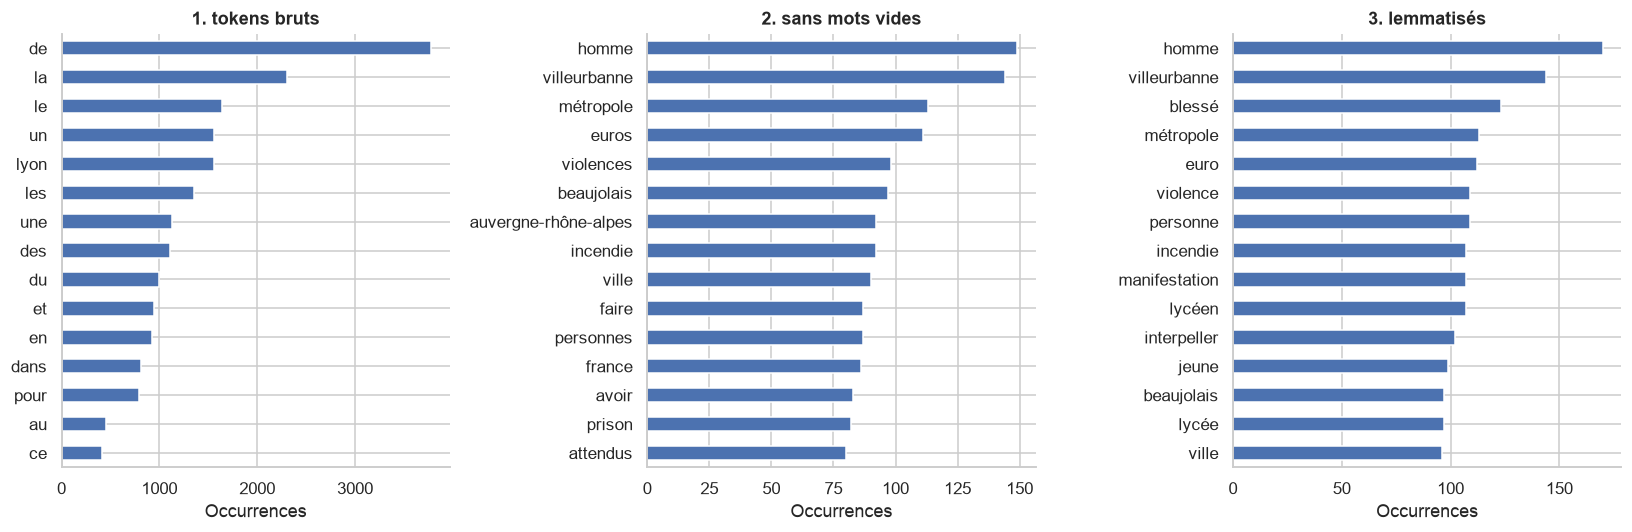

In [3]:
levels = {"1. tokens bruts": "tokens_raw", "2. sans mots vides": "tokens_nostop", "3. lemmatisés": "tokens_lemma"}
counters = {k: Counter(t for ts in df[col] for t in ts) for k, col in levels.items()}
summary = pd.DataFrame({k: {"tokens": sum(c.values()), "vocabulaire": len(c),
                            "mots vus 1 seule fois": sum(1 for v in c.values() if v == 1),
                            "tokens par titre": round(sum(c.values()) / len(df), 1)} for k, c in counters.items()}).T
summary["% du vocabulaire vu 1 fois"] = (100 * summary["mots vus 1 seule fois"] / summary["vocabulaire"]).round(0)
summary.to_csv(TAB / "04_avant_apres_pretraitement.csv"); display(summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (k, c) in zip(axes, counters.items()):
    top = pd.Series(dict(c.most_common(15)))
    top.iloc[::-1].plot.barh(ax=ax, color=sns.color_palette()[0]); ax.set(title=k, xlabel="Occurrences")
plt.tight_layout(); fig.savefig(FIG / "04_avant_apres_top_mots.png", bbox_inches="tight"); plt.show()

## 3. Mots les plus caractéristiques du corpus (lemmes)

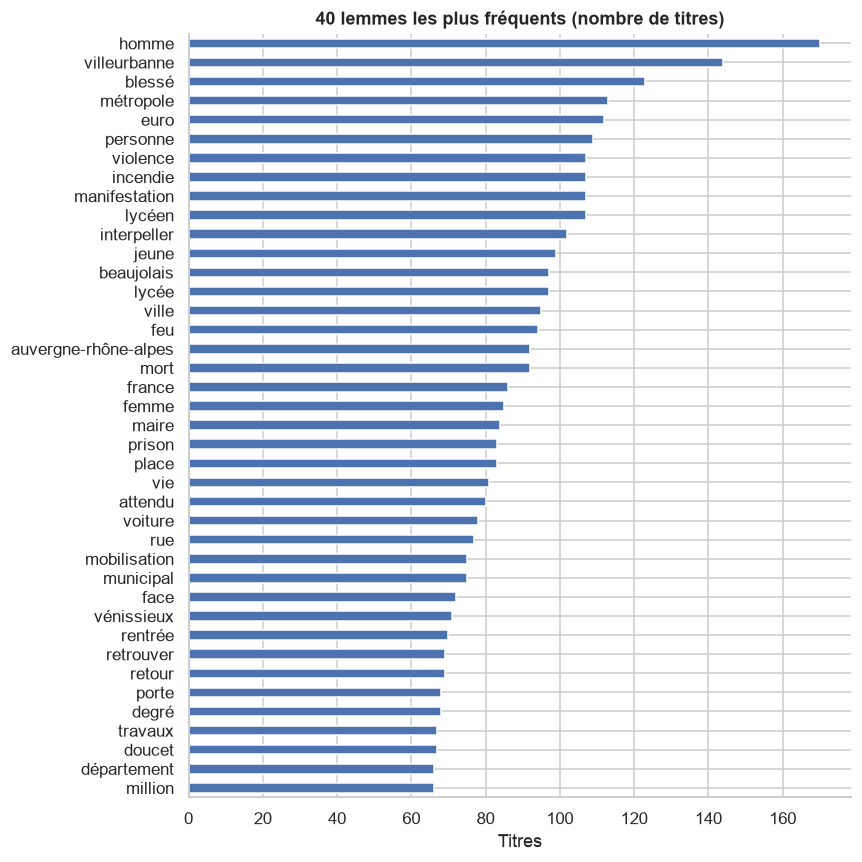

Le lemme le plus fréquent n'apparaît que dans 3.4 % des titres : vocabulaire très diversifié, pas de mot dominant.


In [4]:
# Fréquence documentaire (nombre de titres contenant le lemme) : plus robuste qu'un simple comptage aux répétitions dans un titre
doc_freq = Counter(t for ts in df["tokens_lemma"] for t in set(ts))
top_lemmas = pd.DataFrame(doc_freq.most_common(40), columns=["lemme", "titres"])
top_lemmas["% des titres"] = (100 * top_lemmas["titres"] / len(df)).round(1)
top_lemmas.to_csv(TAB / "04_top_lemmes.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 8))
top_lemmas.iloc[::-1].plot.barh(x="lemme", y="titres", ax=ax, legend=False, color=sns.color_palette()[0])
ax.set(title="40 lemmes les plus fréquents (nombre de titres)", xlabel="Titres", ylabel="")
plt.tight_layout(); fig.savefig(FIG / "04_top_lemmes.png", bbox_inches="tight"); plt.show()
print(f"Le lemme le plus fréquent n'apparaît que dans {top_lemmas['% des titres'].iloc[0]} % des titres : vocabulaire très diversifié, pas de mot dominant.")

## 4. Expressions récurrentes : bigrammes et trigrammes
On cherche les séquences de mots **consécutifs dans le titre d'origine**, en gardant celles qui commencent et finissent par un mot plein (« mise en examen », « fête des Lumières »).
Les bigrammes sont classés de deux façons : par **fréquence** (ce qui revient souvent) et par **PMI** (*pointwise mutual information* : les deux mots apparaissent ensemble bien plus que si
le hasard les associait). La PMI fait remonter les vraies expressions, la fréquence seule fait remonter les combinaisons banales.

In [5]:
SW = french_stopwords()
def ngrams(tokens, n):
    for i in range(len(tokens) - n + 1):
        g = tokens[i:i + n]
        if g[0] not in SW and g[-1] not in SW and len(g[0]) > 2 and len(g[-1]) > 2:
            yield " ".join(g)

uni = Counter(t for ts in df["tokens_raw"] for t in ts)
N = sum(uni.values())
bi = Counter(g for ts in df["tokens_raw"] for g in ngrams(ts, 2))
tri = Counter(g for ts in df["tokens_raw"] for g in ngrams(ts, 3))

def pmi(bigram):
    a, b = bigram.split(" ")
    return np.log2((bi[bigram] / N) / ((uni[a] / N) * (uni[b] / N)))

bi_tab = pd.DataFrame([(g, c, pmi(g)) for g, c in bi.items() if c >= 8], columns=["bigramme", "occurrences", "PMI"]).round(2)
tri_tab = pd.DataFrame(tri.most_common(60), columns=["trigramme", "occurrences"]).query("occurrences >= 4")
bi_tab.sort_values("occurrences", ascending=False).to_csv(TAB / "04_bigrammes.csv", index=False); tri_tab.to_csv(TAB / "04_trigrammes.csv", index=False)
print("Bigrammes les plus fréquents :"); display(bi_tab.sort_values("occurrences", ascending=False).head(15).reset_index(drop=True))
print("Bigrammes à PMI la plus élevée (≥ 8 occurrences) :"); display(bi_tab.sort_values("PMI", ascending=False).head(15).reset_index(drop=True))
print("Trigrammes les plus fréquents :"); display(tri_tab.head(15).reset_index(drop=True))

Bigrammes les plus fréquents :


,bigramme,occurrences,PMI
0,degrés attendus,60,9.50
1,grégory doucet,59,9.85
2,presqu île,43,10.54
3,millions euros,42,8.75
4,départements auvergne-rhône-alpes,31,9.11
5,jeune homme,27,7.85
6,mouvement lycéen,25,10.84
7,conseil municipal,24,10.72
8,mobilisation lycéenne,23,9.11
9,véronique sarselli,21,11.01


Bigrammes à PMI la plus élevée (≥ 8 occurrences) :


,bigramme,occurrences,PMI
0,groupama stadium,8,12.79
1,tiffany joncour,10,12.50
2,fortes chaleurs,11,12.25
3,gilets jaunes,11,12.25
4,tony parker,10,12.15
5,porté disparu,8,12.05
6,ldlc arena,14,11.96
7,poids lourd,9,11.86
8,art contemporain,10,11.82
9,frères coen,8,11.80


Trigrammes les plus fréquents :


,trigramme,occurrences
0,auvergne-rhône-alpes en vigilance,28
1,tour de france,20
2,feux de forêts,17
3,mis en examen,17
4,iris et warren,15
5,mort de quentin,13
6,journées du patrimoine,13
7,villeurbanne un homme,12
8,casernes de pompiers,12
9,place de milan,12


## 5. Comparaison entre médias
Le vocabulaire le plus fréquent d'un média reflète surtout sa ligne éditoriale et son volume. Pour trouver ce qui **distingue** un média des autres, on utilise le **log-odds ratio
avec a priori de Dirichlet informatif** (Monroe, Colaresi & Quinn, 2008) : pour chaque mot, on compare ses odds dans le média à ses odds dans les autres médias,
en ramenant les mots rares vers la fréquence globale du corpus, et on standardise par l'écart-type (z-score). |z| > 2 environ indique une différence peu probablement due au hasard.

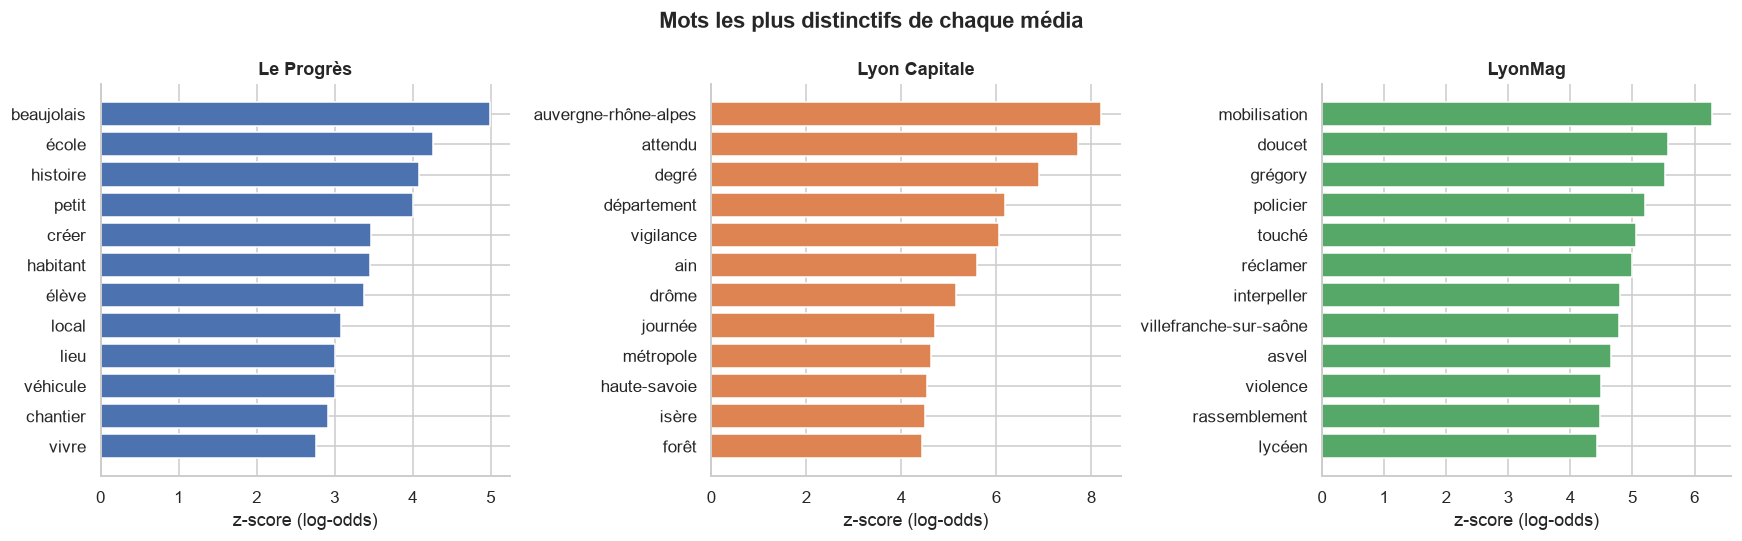

Le Progrès     beaujolais, école, histoire, petit, créer, habitant, élève, local, lieu, véhicule, chantier, vivre
Lyon Capitale  auvergne-rhône-alpes, attendu, degré, département, vigilance, ain, drôme, journée, métropole, haute-savoie, isère, forêt
LyonMag        mobilisation, doucet, grégory, policier, touché, réclamer, interpeller, villefranche-sur-saône, asvel, violence, rassemblement, lycéen


In [6]:
MAIN = ["Le Progrès", "Lyon Capitale", "LyonMag"]
counts = {m: Counter(t for ts in df.loc[df.media_name == m, "tokens_lemma"] for t in ts) for m in MAIN}
vocab = {w for m in MAIN for w, c in counts[m].items()}
total = Counter(); [total.update(c) for c in counts.values()]
A0 = 500                                   # force de l'a priori (en « mots virtuels »)
n_all = sum(total.values())

def log_odds_z(media, min_count=8):
    y_i = counts[media]; n_i = sum(y_i.values())
    y_j = Counter(); [y_j.update(counts[m]) for m in MAIN if m != media]; n_j = sum(y_j.values())
    rows = []
    for w in vocab:
        if total[w] < min_count: continue
        a_w = A0 * total[w] / n_all
        yi, yj = y_i[w], y_j[w]
        d = np.log((yi + a_w) / (n_i + A0 - yi - a_w)) - np.log((yj + a_w) / (n_j + A0 - yj - a_w))
        rows.append((w, yi, yj, d / np.sqrt(1 / (yi + a_w) + 1 / (yj + a_w))))
    return pd.DataFrame(rows, columns=["lemme", "dans_le_média", "dans_les_autres", "z"]).sort_values("z", ascending=False)

dist = {m: log_odds_z(m) for m in MAIN}
pd.concat({m: d.head(12).reset_index(drop=True) for m, d in dist.items()}, axis=1).to_csv(TAB / "04_mots_distinctifs_par_media.csv")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, m in zip(axes, MAIN):
    d = dist[m].head(12).iloc[::-1]
    ax.barh(d["lemme"], d["z"], color=MEDIA_COLORS[m]); ax.set(title=m, xlabel="z-score (log-odds)")
fig.suptitle("Mots les plus distinctifs de chaque média", fontweight="bold")
plt.tight_layout(); fig.savefig(FIG / "04_mots_distinctifs_media.png", bbox_inches="tight"); plt.show()
for m in MAIN: print(f"{m:14s}", ", ".join(dist[m].head(12)["lemme"]))

Ce tableau compare aussi la **fréquence relative** (pour 1 000 mots) de quelques lemmes entre médias, pour vérifier que les différences ne viennent pas des volumes.

In [7]:
probe = [w for w in ["incendie", "manifestation", "violence", "lycée", "métropole", "maire", "euro", "prison", "procès", "police", "grève", "école"] if w in total]
rel = pd.DataFrame({m: {w: 1000 * counts[m][w] / sum(counts[m].values()) for w in probe} for m in MAIN}).round(1)
rel

,Le Progrès,Lyon Capitale,LyonMag
incendie,3.2,3.2,3.4
manifestation,2.4,3.4,4.9
violence,3.0,1.9,6.5
lycée,2.9,2.2,4.4
métropole,1.4,5.5,4.4
maire,2.8,1.9,3.0
euro,1.7,4.5,6.0
prison,1.9,2.2,4.8
procès,0.4,0.2,1.6
police,1.4,1.2,3.5


## 6. Synthèse de l'étape 4

- **Effet du prétraitement** : les mots vides retirent 47 % des tokens (63 812 → 34 019) sans presque réduire le vocabulaire ; la lemmatisation le réduit de 9 440 à 7 232 formes (−23 %). Il reste ≈ 6,7 mots informatifs par titre et **49 % du vocabulaire n'apparaît qu'une fois** : la matrice titres × mots sera très creuse, ce qui annonce des clusters et des topics bruités à l'étape 5.
- **Pas de mot dominant** : le lemme le plus fréquent (« homme ») figure dans 3,4 % des titres seulement. Les lemmes les plus fréquents dessinent les grands registres : faits divers et sécurité (blessé, violence, incendie, interpeller, prison, mort), mobilisation (manifestation, lycéen, lycée) et territoires (Villeurbanne, métropole, Beaujolais).
- **Expressions récurrentes** : on retrouve des **événements et des personnalités** de la période : Grégory Doucet (59), Véronique Sarselli (21), Raphaël Arnault (20), Bruno Bernard (19), « mort de Quentin [Deranque] » (13 trigrammes, 17 occurrences du nom), « mouvement lycéen » (25) et « mobilisation lycéenne » (23), « Auvergne-Rhône-Alpes en vigilance » (28), « feux de forêts » (17), « mis en examen » (17), « Tour de France » (20), « journées du patrimoine » (13), « festival Lumière » (20). Ce sont de bons **candidats à l'émergence** pour l'étape 6.
- **PMI** : elle sépare les vraies expressions (« gilets jaunes », « refus d'obtempérer », « redressement judiciaire », « éclipse solaire ») des couples banals mais fréquents (« millions euros »).
- **Médias** : Le Progrès se distingue par la vie locale et le quotidien (Beaujolais, école, élève, histoire, habitant, chantier) ; Lyon Capitale par l'information régionale et les alertes (Auvergne-Rhône-Alpes, vigilance, degré, Ain, Drôme, Isère, Haute-Savoie) ; LyonMag par la politique locale et la sécurité (mobilisation, Doucet, policier, violence, rassemblement, ASVEL). Exemple de fréquences relatives : « violence » = 6,5 pour 1 000 mots dans LyonMag contre 3,0 au Progrès et 1,9 à Lyon Capitale.
- **Précautions** : une partie de ces différences est **de format éditorial** (bulletins météo/vigilance de Lyon Capitale), pas de « sujet » ; les n-grammes traversent la ponctuation (« Villeurbanne un homme ») ; `simplemma` lemmatise par dictionnaire, sans contexte, donc quelques erreurs subsistent.